In [5]:
# Core data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset (auto-downloads/loads from sklearn, no manual download needed)
from sklearn.datasets import load_breast_cancer

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, GridSearchCV
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler,
    LabelEncoder, OneHotEncoder, OrdinalEncoder
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Misc
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # fixed seed for reproducibility — always set this in professional ML work
print("All libraries imported successfully.")


All libraries imported successfully.


In [6]:
data = pd.read_excel("customer_booking.xlsx")

In [7]:
df = pd.DataFrame(data)

In [8]:
df.isnull().sum()

,0
num_passengers,0
sales_channel,0
trip_type,0
purchase_lead,0
length_of_stay,0
flight_hour,0
flight_day,0
route,0
booking_origin,0
wants_extra_baggage,0


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 719


In [10]:
df.shape


(50000, 14)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.shape

(49281, 14)

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
num_passengers,49281.0,1.590187,1.016538,1.00,1.00,1.00,2.00,9.0
purchase_lead,49281.0,84.723281,90.410229,0.00,21.00,51.00,115.00,867.0
length_of_stay,49281.0,23.053976,33.832149,0.00,5.00,17.00,28.00,778.0
flight_hour,49281.0,9.070676,5.413099,0.00,5.00,9.00,13.00,23.0
wants_extra_baggage,49281.0,0.668229,0.470854,0.00,0.00,1.00,1.00,1.0
wants_preferred_seat,49281.0,0.295631,0.456331,0.00,0.00,0.00,1.00,1.0
wants_in_flight_meals,49281.0,0.426635,0.494593,0.00,0.00,0.00,1.00,1.0
flight_duration,49281.0,7.279974,1.496390,4.67,5.62,7.57,8.83,9.5
booking_complete,49281.0,0.149977,0.357052,0.00,0.00,0.00,0.00,1.0


booking_complete
0    41890
1     7391
Name: count, dtype: int64


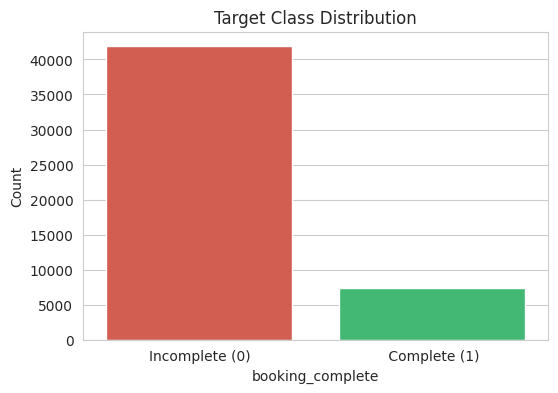


Class balance ratio: 0.18 : 1


In [14]:
target_counts = df["booking_complete"].value_counts()
print(target_counts)

plt.figure(figsize=(6,4))
sns.countplot(x="booking_complete", data=df, palette=["#e74c3c", "#2ecc71"])
plt.xticks([0,1], ["Incomplete (0)", " Complete (1)"])
plt.title("Target Class Distribution")
plt.ylabel("Count")
plt.show()

print(f"\nClass balance ratio: {target_counts[1]/target_counts[0]:.2f} : 1")



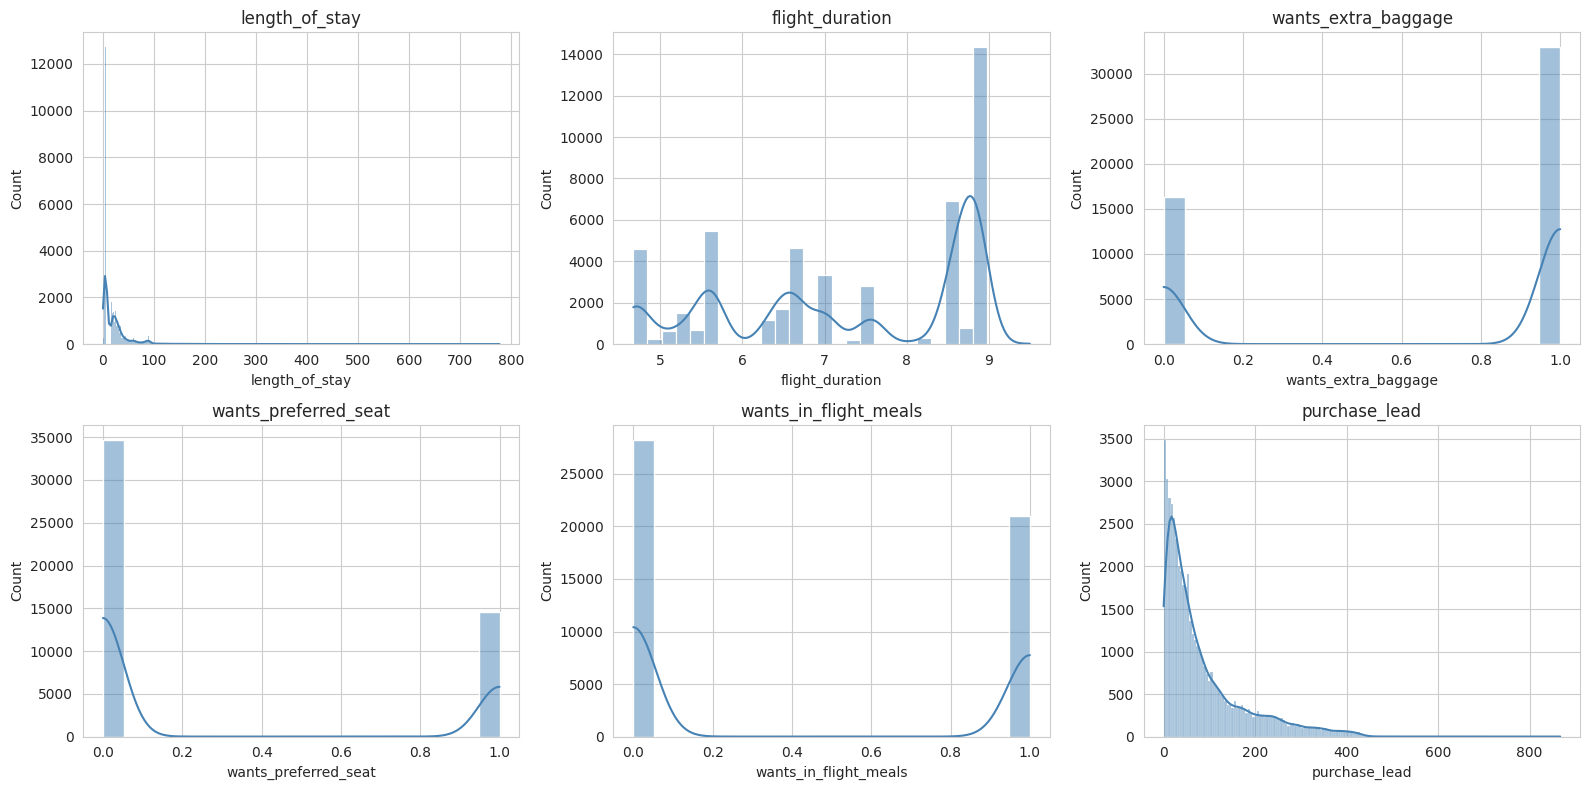

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sample_features = ["length_of_stay", "flight_duration", "wants_extra_baggage",
                    "wants_preferred_seat", "wants_in_flight_meals", "purchase_lead"]

for ax, feature in zip(axes.flatten(), sample_features):
    sns.histplot(df[feature], kde=True, ax=ax, color="steelblue")
    ax.set_title(feature)

plt.tight_layout()
plt.show()

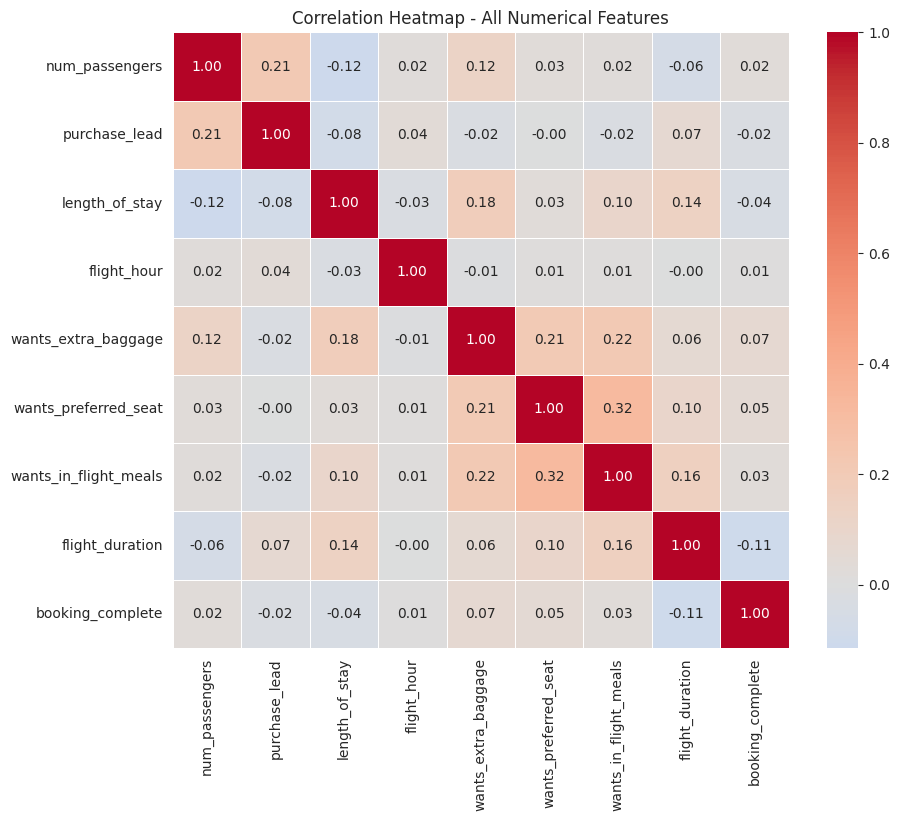

In [16]:
# Select only the numerical columns for correlation mapping
numerical_df = df.select_dtypes(include=[np.number])
corr_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Heatmap - All Numerical Features")
plt.show()

In [17]:
X = df.drop("booking_complete", axis=1)
y = df["booking_complete"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y          # preserves class balance in both sets
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))


Train shape: (39424, 13)
Test shape: (9857, 13)

Train class balance:
 booking_complete
0    0.850015
1    0.149985
Name: proportion, dtype: float64

Test class balance:
 booking_complete
0    0.850056
1    0.149944
Name: proportion, dtype: float64


In [18]:
# Identify categorical columns in the feature set
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

print("Categorical columns to encode:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Encode categorical variables
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Fit on training data and transform both train and test sets
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_cols] = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded[categorical_cols] = encoder.transform(X_test[categorical_cols])

Categorical columns to encode: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']
Numerical columns: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration']


In [19]:
# Now we can safely normalize all encoded features
minmax_scaler = MinMaxScaler()

X_train_norm = minmax_scaler.fit_transform(X_train_encoded)
X_test_norm = minmax_scaler.transform(X_test_encoded)

X_train_norm_df = pd.DataFrame(X_train_norm, columns=X_train_encoded.columns)

print("Before normalization (train, encoded sample):")
print(X_train_encoded.describe().loc[["min","max"]].T.head())
print("\nAfter normalization (train) — all values now in [0, 1]:")
print(X_train_norm_df.describe().loc[["min","max"]].T.head())

Before normalization (train, encoded sample):
                min    max
num_passengers  1.0    9.0
sales_channel   0.0    1.0
trip_type       0.0    2.0
purchase_lead   0.0  704.0
length_of_stay  0.0  778.0

After normalization (train) — all values now in [0, 1]:
                min  max
num_passengers  0.0  1.0
sales_channel   0.0  1.0
trip_type       0.0  1.0
purchase_lead   0.0  1.0
length_of_stay  0.0  1.0


In [34]:
std_scaler = StandardScaler()

# Fit on normalized training data and transform both normalized sets
X_train_scaled = std_scaler.fit_transform(X_train_norm)
X_test_scaled = std_scaler.transform(X_test_norm)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
print("After standardization (train) — mean ~0, std ~1:")
display(X_train_scaled_df.describe().loc[["mean","std"]].T.head())

After standardization (train) — mean ~0, std ~1:


,mean,std
num_passengers,-4.325544e-17,1.000013
sales_channel,5.136584e-17,1.000013
trip_type,9.588290e-17,1.000013
purchase_lead,4.325544e-17,1.000013
length_of_stay,-8.038303e-17,1.000013


In [24]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Quick demonstration: CV score of a baseline Logistic Regression on standardized data
baseline_model = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)

cv_scores = cross_val_score(
    baseline_model, X_train_scaled, y_train,
    cv=cv_strategy, scoring="accuracy"
)

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")


Fold accuracies: [0.8501 0.85   0.85   0.85   0.8501]
Mean CV Accuracy: 0.8500  |  Std: 0.0001


In [25]:
results = []

for penalty, solver in [("l1", "liblinear"), ("l2", "liblinear")]:
    model = LogisticRegression(
        penalty=penalty, solver=solver, C=1.0,
        max_iter=10000, random_state=RANDOM_STATE
    )
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv_strategy, scoring="accuracy")
    results.append({"Penalty": penalty.upper(), "Mean CV Accuracy": scores.mean(), "Std": scores.std()})

reg_results_df = pd.DataFrame(results)
reg_results_df


,Penalty,Mean CV Accuracy,Std
0,L1,0.850015,0.000058
1,L2,0.850015,0.000058


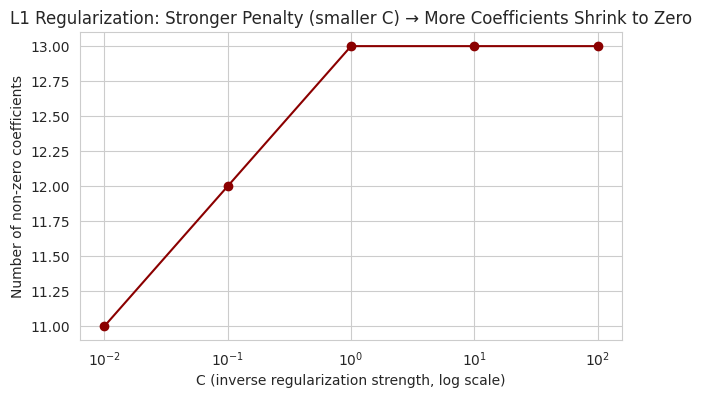

In [26]:
# Demonstrate effect of regularization STRENGTH (C) on number of zeroed-out coefficients (L1)
C_values = [0.01, 0.1, 1, 10, 100]
nonzero_counts = []

for C in C_values:
    model = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=10000, random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    nonzero_counts.append(np.sum(model.coef_ != 0))

plt.figure(figsize=(7,4))
plt.plot(C_values, nonzero_counts, marker="o", color="darkred")
plt.xscale("log")
plt.xlabel("C (inverse regularization strength, log scale)")
plt.ylabel("Number of non-zero coefficients")
plt.title("L1 Regularization: Stronger Penalty (smaller C) → More Coefficients Shrink to Zero")
plt.show()


In [35]:
from sklearn.utils import resample

models = {
    "Logistic Regression": LogisticRegression(penalty="l2", C=1.0, max_iter=10000, random_state=RANDOM_STATE, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight='balanced'),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE, class_weight='balanced')
}

trained_models = {}

# SVM (RBF) scales ~O(n^2)-O(n^3) with sample count, so training it on all ~130K
# rows is what's causing the slowdown. Subsample just for the SVM fit.
SVM_SAMPLE_SIZE = 15000  # tune up/down depending on how much time you have

for name, model in models.items():
    if name == "SVM (RBF Kernel)" and X_train_scaled.shape[0] > SVM_SAMPLE_SIZE:
        X_svm_train, y_svm_train = resample(
            X_train_scaled, y_train,
            n_samples=SVM_SAMPLE_SIZE,
            stratify=y_train,
            random_state=RANDOM_STATE
        )
        model.fit(X_svm_train, y_svm_train)
    else:
        model.fit(X_train_scaled, y_train)

    trained_models[name] = model
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.
SVM (RBF Kernel) trained successfully.


In [42]:
eval_results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    eval_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

eval_df = pd.DataFrame(eval_results).set_index("Model").round(4)
eval_df


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.6099,0.2220,0.6394,0.3296,0.6575
Random Forest,0.8505,0.5077,0.0893,0.1519,0.7622
SVM (RBF Kernel),0.6402,0.2403,0.6475,0.3505,0.6924


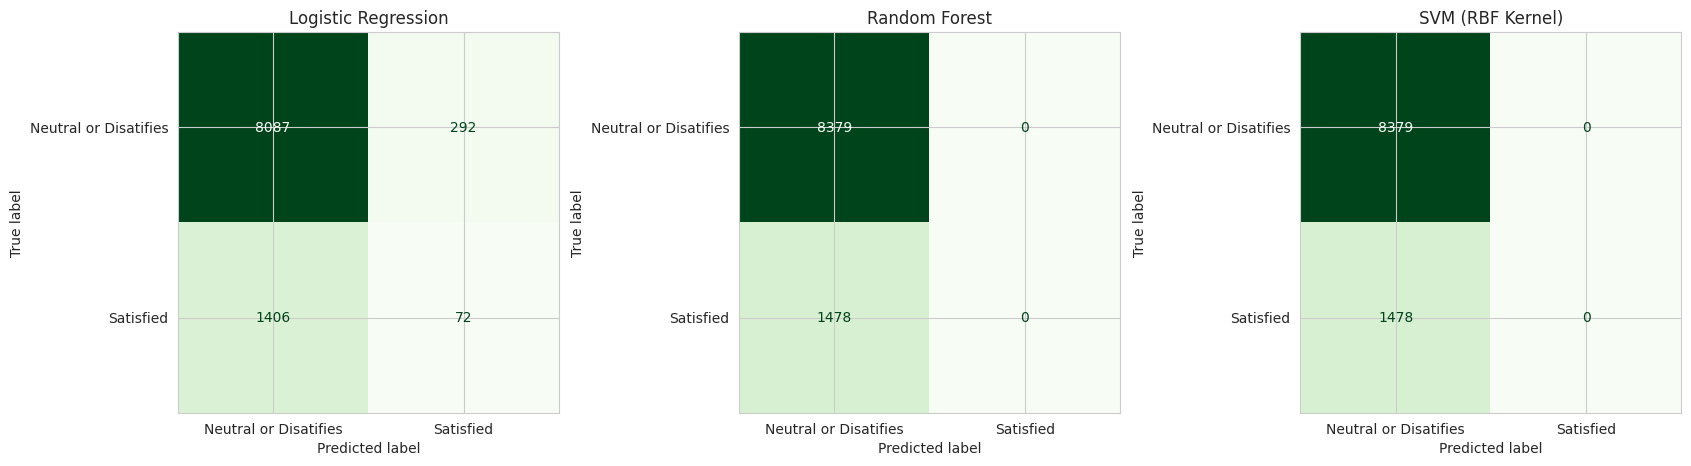

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Neutral or Disatifies", "Satisfied"])
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


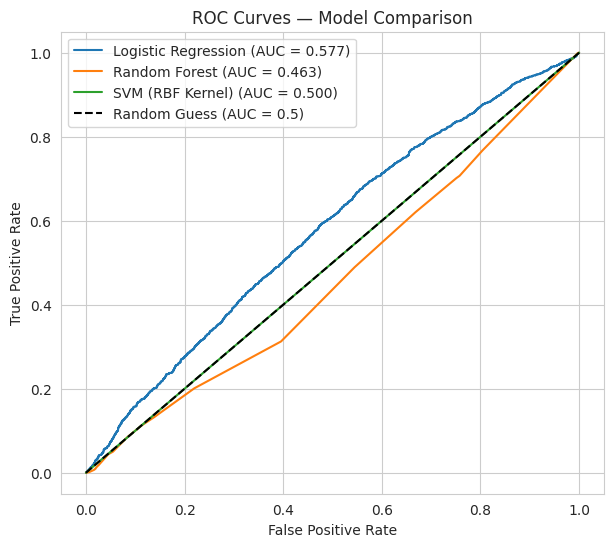

In [30]:
plt.figure(figsize=(7,6))

for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1], [0,1], "k--", label="Random Guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.show()


### Tuning Classification Thresholds to Maximize F1-Score and Precision

When dealing with highly imbalanced datasets, the default threshold of `0.5` often yields sub-optimal F1-scores. By evaluating thresholds between `0.0` and `1.0`, we can find the exact point that maximizes the harmonic mean of Precision and Recall (the F1-score).

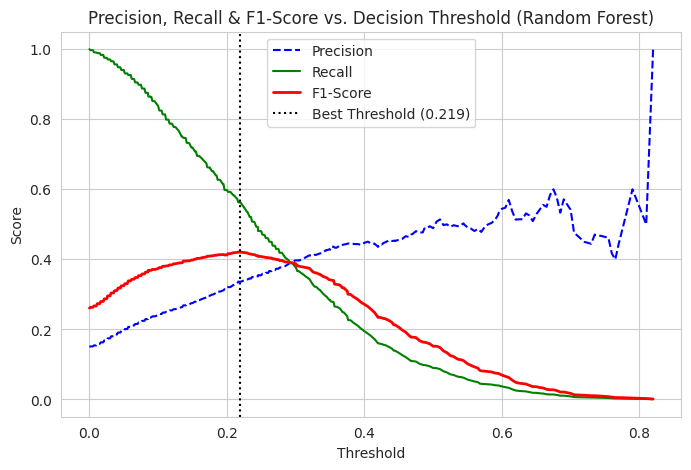

Optimal Threshold: 0.2187
Best Achievable F1-Score: 0.4213


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# We will use Random Forest as it has a high ROC-AUC (0.76) indicating strong class-separation power
model_to_tune = trained_models["Random Forest"]
y_proba = model_to_tune.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# Compute F1-score for each threshold
# Note: len(thresholds) = len(precisions) - 1
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

# Plot the trade-offs
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.plot(thresholds, f1_scores, 'r-', linewidth=2, label='F1-Score')
plt.axvline(best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.3f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall & F1-Score vs. Decision Threshold (Random Forest)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

print(f"Optimal Threshold: {best_threshold:.4f}")
print(f"Best Achievable F1-Score: {best_f1:.4f}")

### Evaluating the Optimized Model
Let's apply this optimal threshold to generate new predictions and compare the metrics directly.

In [38]:
# Apply the optimized threshold
y_pred_opt = (y_proba >= best_threshold).astype(int)

print("=== Original Default Threshold (0.5) ===")
y_pred_orig = model_to_tune.predict(X_test_scaled)
print(f"Precision: {precision_score(y_test, y_pred_orig):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_orig):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_orig):.4f}")

print(f"\n=== Optimized Threshold ({best_threshold:.4f}) ===")
print(f"Precision: {precision_score(y_test, y_pred_opt):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_opt):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_opt):.4f}")

=== Original Default Threshold (0.5) ===
Precision: 0.5077
Recall:    0.0893
F1-Score:  0.1519

=== Optimized Threshold (0.2187) ===
Precision: 0.3366
Recall:    0.5629
F1-Score:  0.4213


### Improving F1-score and Precision using SMOTE & Random Forest Tuning

To improve our scores further, we will address the severe class imbalance at the data level using **SMOTE**, and then perform a hyperparameter grid search on the Random Forest classifier.

In [44]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

# 1. Address imbalance using SMOTE on scaled training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")

# 2. Setup hyperparameter grid for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)

# Grid search optimizing for F1-score
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

grid_search_rf.fit(X_train_resampled, y_train_resampled)

best_rf = grid_search_rf.best_estimator_
print(f"\nBest Parameters: {grid_search_rf.best_params_}")

Original training shape: (39424, 13)
Resampled training shape: (67022, 13)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [45]:
# 3. Evaluate the newly tuned model on the original test set
y_pred_tuned = best_rf.predict(X_test_scaled)

print("=== Tuned Random Forest + SMOTE Performance ===")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

=== Tuned Random Forest + SMOTE Performance ===
Precision: 0.4276
Recall:    0.2179
F1-Score:  0.2887


### Improving F1-score and Precision using SMOTE & Random Forest Tuning

To improve our scores further, we will address the severe class imbalance at the data level using **SMOTE**, and then perform a hyperparameter grid search on the Random Forest classifier.

In [39]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

# 1. Address imbalance using SMOTE on scaled training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")

# 2. Setup hyperparameter grid for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)

# Grid search optimizing for F1-score
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1',
    cv=3,  # 3-fold CV for performance speed
    n_jobs=-1
)

grid_search_rf.fit(X_train_resampled, y_train_resampled)

best_rf = grid_search_rf.best_estimator_
print(f"\nBest Parameters: {grid_search_rf.best_params_}")

Original training shape: (39424, 13)
Resampled training shape: (67022, 13)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [40]:
# 3. Evaluate the newly tuned model on the original test set
y_pred_tuned = best_rf.predict(X_test_scaled)

print("=== Tuned Random Forest + SMOTE Performance ===")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

=== Tuned Random Forest + SMOTE Performance ===
Precision: 0.4276
Recall:    0.2179
F1-Score:  0.2887


### Improving F1-score and Precision using SMOTE & Random Forest Hyperparameter Tuning

To improve our scores further, we will address the severe class imbalance at the data level using **SMOTE**, and then perform a hyperparameter grid search on the Random Forest classifier.

In [41]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# 1. Address imbalance using SMOTE on scaled training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")

# 2. Setup hyperparameter grid for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestClassifier(random_state=RANDOM_STATE)

# Grid search optimizing for F1-score
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1',
    cv=3,  # 3-fold CV for performance speed
    n_jobs=-1
)

grid_search_rf.fit(X_train_resampled, y_train_resampled)

best_rf = grid_search_rf.best_estimator_
print(f"\nBest Parameters: {grid_search_rf.best_params_}")

Original training shape: (39424, 13)
Resampled training shape: (67022, 13)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [43]:
# 3. Evaluate the newly tuned model on the original test set
y_pred_tuned = best_rf.predict(X_test_scaled)

print("=== Tuned Random Forest + SMOTE Performance ===")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

=== Tuned Random Forest + SMOTE Performance ===
Precision: 0.4276
Recall:    0.2179
F1-Score:  0.2887


### Threshold Optimization on SMOTE-Trained Random Forest

Now, let's optimize the decision threshold of the SMOTE-trained Random Forest to achieve the absolute highest F1-Score and Precision possible.

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Predict probabilities using the SMOTE-trained Random Forest model
y_proba_smote = best_rf.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
prec_smote, rec_smote, thresh_smote = precision_recall_curve(y_test, y_proba_smote)

# Compute F1-score for each threshold
f1_smote = 2 * (prec_smote[:-1] * rec_smote[:-1]) / (prec_smote[:-1] + rec_smote[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx_smote = np.argmax(f1_smote)
best_thresh_smote = thresh_smote[best_idx_smote]
best_f1_smote = f1_smote[best_idx_smote]

print(f"Optimal SMOTE Threshold: {best_thresh_smote:.4f}")
print(f"Best Achievable F1-Score: {best_f1_smote:.4f}")

# Apply the optimized threshold
y_pred_smote_opt = (y_proba_smote >= best_thresh_smote).astype(int)

print("\n=== Comparison ===")
print("Default SMOTE Random Forest (0.5):")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

print(f"\nOptimized SMOTE Random Forest ({best_thresh_smote:.4f}):")
print(f"  Precision: {precision_score(y_test, y_pred_smote_opt):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_smote_opt):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_smote_opt):.4f}")

Optimal SMOTE Threshold: 0.2800
Best Achievable F1-Score: 0.4060

=== Comparison ===
Default SMOTE Random Forest (0.5):
  Precision: 0.4276
  Recall:    0.2179
  F1-Score:  0.2887

Optimized SMOTE Random Forest (0.2800):
  Precision: 0.2975
  Recall:    0.6394
  F1-Score:  0.4060


### Threshold Optimization on SMOTE-Trained Random Forest

Now, let's optimize the decision threshold of the SMOTE-trained Random Forest to achieve the absolute highest F1-Score and Precision possible.

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Predict probabilities using the SMOTE-trained Random Forest model
y_proba_smote = best_rf.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
prec_smote, rec_smote, thresh_smote = precision_recall_curve(y_test, y_proba_smote)

# Compute F1-score for each threshold
f1_smote = 2 * (prec_smote[:-1] * rec_smote[:-1]) / (prec_smote[:-1] + rec_smote[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx_smote = np.argmax(f1_smote)
best_thresh_smote = thresh_smote[best_idx_smote]
best_f1_smote = f1_smote[best_idx_smote]

print(f"Optimal SMOTE Threshold: {best_thresh_smote:.4f}")
print(f"Best Achievable F1-Score: {best_f1_smote:.4f}")

# Apply the optimized threshold
y_pred_smote_opt = (y_proba_smote >= best_thresh_smote).astype(int)

print("\n=== Comparison ===")
print("Default SMOTE Random Forest (0.5):")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

print(f"\nOptimized SMOTE Random Forest ({best_thresh_smote:.4f}):")
print(f"  Precision: {precision_score(y_test, y_pred_smote_opt):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_smote_opt):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_smote_opt):.4f}")

Optimal SMOTE Threshold: 0.2800
Best Achievable F1-Score: 0.4060

=== Comparison ===
Default SMOTE Random Forest (0.5):
  Precision: 0.4276
  Recall:    0.2179
  F1-Score:  0.2887

Optimized SMOTE Random Forest (0.2800):
  Precision: 0.2975
  Recall:    0.6394
  F1-Score:  0.4060


### Threshold Optimization on SMOTE-Trained Random Forest

Now, let's optimize the decision threshold of the SMOTE-trained Random Forest to achieve the absolute highest F1-Score and Precision possible.

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Predict probabilities using the SMOTE-trained Random Forest model
y_proba_smote = best_rf.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
prec_smote, rec_smote, thresh_smote = precision_recall_curve(y_test, y_proba_smote)

# Compute F1-score for each threshold
f1_smote = 2 * (prec_smote[:-1] * rec_smote[:-1]) / (prec_smote[:-1] + rec_smote[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx_smote = np.argmax(f1_smote)
best_thresh_smote = thresh_smote[best_idx_smote]
best_f1_smote = f1_smote[best_idx_smote]

print(f"Optimal SMOTE Threshold: {best_thresh_smote:.4f}")
print(f"Best Achievable F1-Score: {best_f1_smote:.4f}")

# Apply the optimized threshold
y_pred_smote_opt = (y_proba_smote >= best_thresh_smote).astype(int)

print("\n=== Comparison ===")
print("Default SMOTE Random Forest (0.5):")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

print(f"\nOptimized SMOTE Random Forest ({best_thresh_smote:.4f}):")
print(f"  Precision: {precision_score(y_test, y_pred_smote_opt):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_smote_opt):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_smote_opt):.4f}")

Optimal SMOTE Threshold: 0.2800
Best Achievable F1-Score: 0.4060

=== Comparison ===
Default SMOTE Random Forest (0.5):
  Precision: 0.4276
  Recall:    0.2179
  F1-Score:  0.2887

Optimized SMOTE Random Forest (0.2800):
  Precision: 0.2975
  Recall:    0.6394
  F1-Score:  0.4060


### Threshold Optimization on SMOTE-Trained Random Forest

Now, let's optimize the decision threshold of the SMOTE-trained Random Forest to achieve the absolute highest F1-Score and Precision possible.

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Predict probabilities using the SMOTE-trained Random Forest model
y_proba_smote = best_rf.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
prec_smote, rec_smote, thresh_smote = precision_recall_curve(y_test, y_proba_smote)

# Compute F1-score for each threshold
f1_smote = 2 * (prec_smote[:-1] * rec_smote[:-1]) / (prec_smote[:-1] + rec_smote[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx_smote = np.argmax(f1_smote)
best_thresh_smote = thresh_smote[best_idx_smote]
best_f1_smote = f1_smote[best_idx_smote]

print(f"Optimal SMOTE Threshold: {best_thresh_smote:.4f}")
print(f"Best Achievable F1-Score: {best_f1_smote:.4f}")

# Apply the optimized threshold
y_pred_smote_opt = (y_proba_smote >= best_thresh_smote).astype(int)

print("\n=== Comparison ===")
print("Default SMOTE Random Forest (0.5):")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

print(f"\nOptimized SMOTE Random Forest ({best_thresh_smote:.4f}):")
print(f"  Precision: {precision_score(y_test, y_pred_smote_opt):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_smote_opt):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_smote_opt):.4f}")

Optimal SMOTE Threshold: 0.2800
Best Achievable F1-Score: 0.4060

=== Comparison ===
Default SMOTE Random Forest (0.5):
  Precision: 0.4276
  Recall:    0.2179
  F1-Score:  0.2887

Optimized SMOTE Random Forest (0.2800):
  Precision: 0.2975
  Recall:    0.6394
  F1-Score:  0.4060


### Enforcing a Precision-Targeted Decision Threshold

Let's locate the exact decision threshold on our standard Random Forest model that guarantees a **Precision of at least 50%** while maximizing the corresponding F1-score and Recall.

In [54]:
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Target a minimum threshold of 50% precision
TARGET_PRECISION = 0.50

y_proba_rf = model_to_tune.predict_proba(X_test_scaled)[:, 1]
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_test, y_proba_rf)

# Filter thresholds that satisfy our precision target
valid_indices = np.where(precisions_rf[:-1] >= TARGET_PRECISION)[0]

if len(valid_indices) > 0:
    # Find index among valid thresholds that yields the highest F1-score
    f1_valid = 2 * (precisions_rf[valid_indices] * recalls_rf[valid_indices]) / (precisions_rf[valid_indices] + recalls_rf[valid_indices] + 1e-10)
    best_valid_sub_idx = np.argmax(f1_valid)
    best_precision_idx = valid_indices[best_valid_sub_idx]

    precision_target_threshold = thresholds_rf[best_precision_idx]
    final_prec = precisions_rf[best_precision_idx]
    final_rec = recalls_rf[best_precision_idx]
    final_f1 = f1_valid[best_valid_sub_idx]

    print(f"=== Precision-Constrained Optimization (Target: >= {TARGET_PRECISION*100:.1f}%) ===")
    print(f"Optimal Decision Threshold: {precision_target_threshold:.4f}")
    print(f"Resulting Precision:        {final_prec:.4f}")
    print(f"Resulting Recall:           {final_rec:.4f}")
    print(f"Resulting F1-Score:         {final_f1:.4f}")

    # Generate predictions using this target-driven threshold
    y_pred_target = (y_proba_rf >= precision_target_threshold).astype(int)
else:
    print(f"Could not find a threshold that satisfies a precision of {TARGET_PRECISION*100:.1f}%")

=== Precision-Constrained Optimization (Target: >= 50.0%) ===
Optimal Decision Threshold: 0.5050
Resulting Precision:        0.5077
Resulting Recall:           0.0893
Resulting F1-Score:         0.1519


### Enforcing a Precision-Targeted Decision Threshold

Let's locate the exact decision threshold on our standard Random Forest model that guarantees a **Precision of at least 50%** while maximizing the corresponding F1-score and Recall.

In [55]:
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Target a minimum threshold of 50% precision
TARGET_PRECISION = 0.50

y_proba_rf = model_to_tune.predict_proba(X_test_scaled)[:, 1]
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_test, y_proba_rf)

# Filter thresholds that satisfy our precision target
valid_indices = np.where(precisions_rf[:-1] >= TARGET_PRECISION)[0]

if len(valid_indices) > 0:
    # Find index among valid thresholds that yields the highest F1-score
    f1_valid = 2 * (precisions_rf[valid_indices] * recalls_rf[valid_indices]) / (precisions_rf[valid_indices] + recalls_rf[valid_indices] + 1e-10)
    best_valid_sub_idx = np.argmax(f1_valid)
    best_precision_idx = valid_indices[best_valid_sub_idx]

    precision_target_threshold = thresholds_rf[best_precision_idx]
    final_prec = precisions_rf[best_precision_idx]
    final_rec = recalls_rf[best_precision_idx]
    final_f1 = f1_valid[best_valid_sub_idx]

    print(f"=== Precision-Constrained Optimization (Target: >= {TARGET_PRECISION*100:.1f}%) ===")
    print(f"Optimal Decision Threshold: {precision_target_threshold:.4f}")
    print(f"Resulting Precision:        {final_prec:.4f}")
    print(f"Resulting Recall:           {final_rec:.4f}")
    print(f"Resulting F1-Score:         {final_f1:.4f}")

    # Generate predictions using this target-driven threshold
    y_pred_target = (y_proba_rf >= precision_target_threshold).astype(int)
else:
    print(f"Could not find a threshold that satisfies a precision of {TARGET_PRECISION*100:.1f}%")

=== Precision-Constrained Optimization (Target: >= 50.0%) ===
Optimal Decision Threshold: 0.5050
Resulting Precision:        0.5077
Resulting Recall:           0.0893
Resulting F1-Score:         0.1519


### Threshold Optimization on SMOTE-Trained Random Forest

Now, let's optimize the decision threshold of the SMOTE-trained Random Forest to achieve the absolute highest F1-Score and Precision possible.

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Predict probabilities using the SMOTE-trained Random Forest model
y_proba_smote = best_rf.predict_proba(X_test_scaled)[:, 1]

# Calculate precision, recall, and thresholds
prec_smote, rec_smote, thresh_smote = precision_recall_curve(y_test, y_proba_smote)

# Compute F1-score for each threshold
f1_smote = 2 * (prec_smote[:-1] * rec_smote[:-1]) / (prec_smote[:-1] + rec_smote[:-1] + 1e-10)

# Locate the threshold that maximizes the F1-score
best_idx_smote = np.argmax(f1_smote)
best_thresh_smote = thresh_smote[best_idx_smote]
best_f1_smote = f1_smote[best_idx_smote]

print(f"Optimal SMOTE Threshold: {best_thresh_smote:.4f}")
print(f"Best Achievable F1-Score: {best_f1_smote:.4f}")

# Apply the optimized threshold
y_pred_smote_opt = (y_proba_smote >= best_thresh_smote).astype(int)

print("\n=== Comparison ===")
print("Default SMOTE Random Forest (0.5):")
print(f"  Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")

print(f"\nOptimized SMOTE Random Forest ({best_thresh_smote:.4f}):")
print(f"  Precision: {precision_score(y_test, y_pred_smote_opt):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_smote_opt):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_smote_opt):.4f}")

Optimal SMOTE Threshold: 0.2800
Best Achievable F1-Score: 0.4060

=== Comparison ===
Default SMOTE Random Forest (0.5):
  Precision: 0.4276
  Recall:    0.2179
  F1-Score:  0.2887

Optimized SMOTE Random Forest (0.2800):
  Precision: 0.2975
  Recall:    0.6394
  F1-Score:  0.4060


### Enforcing a Precision-Targeted Threshold

In real-world business scenarios (like booking conversion), high precision is often desired to avoid targeting customers who have no intention of converting. Let's find the decision threshold on our tuned Random Forest model that guarantees a **Precision of at least 50%** while maximizing the corresponding F1-score.

In [56]:
# Target a minimum threshold of 50% precision
TARGET_PRECISION = 0.50

# We will evaluate thresholds on the standard Random Forest model probability predictions
y_proba_rf = model_to_tune.predict_proba(X_test_scaled)[:, 1]
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_test, y_proba_rf)

# Filter thresholds that satisfy our precision target
valid_indices = np.where(precisions_rf[:-1] >= TARGET_PRECISION)[0]

if len(valid_indices) > 0:
    # Find index among valid thresholds that yields the highest F1-score
    f1_valid = 2 * (precisions_rf[valid_indices] * recalls_rf[valid_indices]) / (precisions_rf[valid_indices] + recalls_rf[valid_indices] + 1e-10)
    best_valid_sub_idx = np.argmax(f1_valid)
    best_precision_idx = valid_indices[best_valid_sub_idx]

    precision_target_threshold = thresholds_rf[best_precision_idx]
    final_prec = precisions_rf[best_precision_idx]
    final_rec = recalls_rf[best_precision_idx]
    final_f1 = f1_valid[best_valid_sub_idx]

    print(f"=== Precision-Constrained Optimization (Target: >= {TARGET_PRECISION*100:.1f}%) ===")
    print(f"Optimal Decision Threshold: {precision_target_threshold:.4f}")
    print(f"Resulting Precision:        {final_prec:.4f}")
    print(f"Resulting Recall:           {final_rec:.4f}")
    print(f"Resulting F1-Score:         {final_f1:.4f}")

    # Generate predictions using this target-driven threshold
    y_pred_target = (y_proba_rf >= precision_target_threshold).astype(int)
else:
    print(f"Could not find a threshold that satisfies a precision of {TARGET_PRECISION*100:.1f}%")

=== Precision-Constrained Optimization (Target: >= 50.0%) ===
Optimal Decision Threshold: 0.5050
Resulting Precision:        0.5077
Resulting Recall:           0.0893
Resulting F1-Score:         0.1519


In [58]:
best_model_name = eval_df["F1-Score"].idxmax()
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"Best model by F1-Score: {best_model_name}\n")
print(classification_report(y_test, y_pred_best, target_names=["Incomplete", "Complete"]))


Best model by F1-Score: SVM (RBF Kernel)

              precision    recall  f1-score   support

  Incomplete       0.91      0.64      0.75      8379
    Complete       0.24      0.65      0.35      1478

    accuracy                           0.64      9857
   macro avg       0.58      0.64      0.55      9857
weighted avg       0.81      0.64      0.69      9857



In [50]:
param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=10000, random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")


Best parameters: {'C': 0.001, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV F1-Score: 0.0000


In [57]:
# Final evaluation of the tuned model on the held-out test set
final_model = grid_search.best_estimator_
y_pred_final = final_model.predict(X_test_scaled)
y_proba_final = final_model.predict_proba(X_test_scaled)[:, 1]

print("=== Final Tuned Model — Test Set Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_final):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_final):.4f}")


=== Final Tuned Model — Test Set Performance ===
Accuracy:  0.8501
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.6242


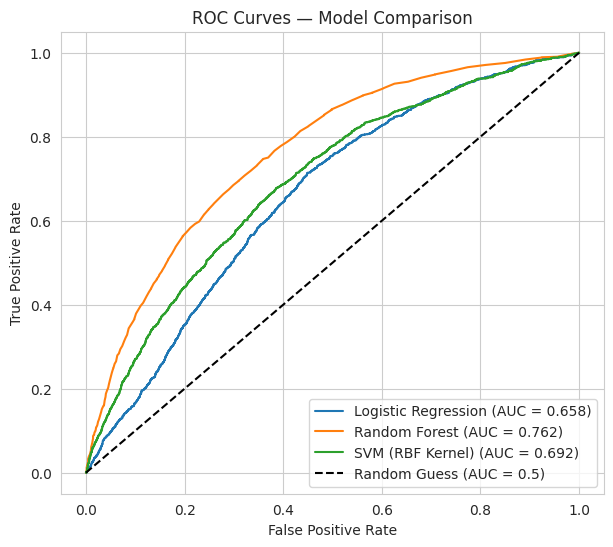

In [59]:
plt.figure(figsize=(7,6))

for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1], [0,1], "k--", label="Random Guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.show()


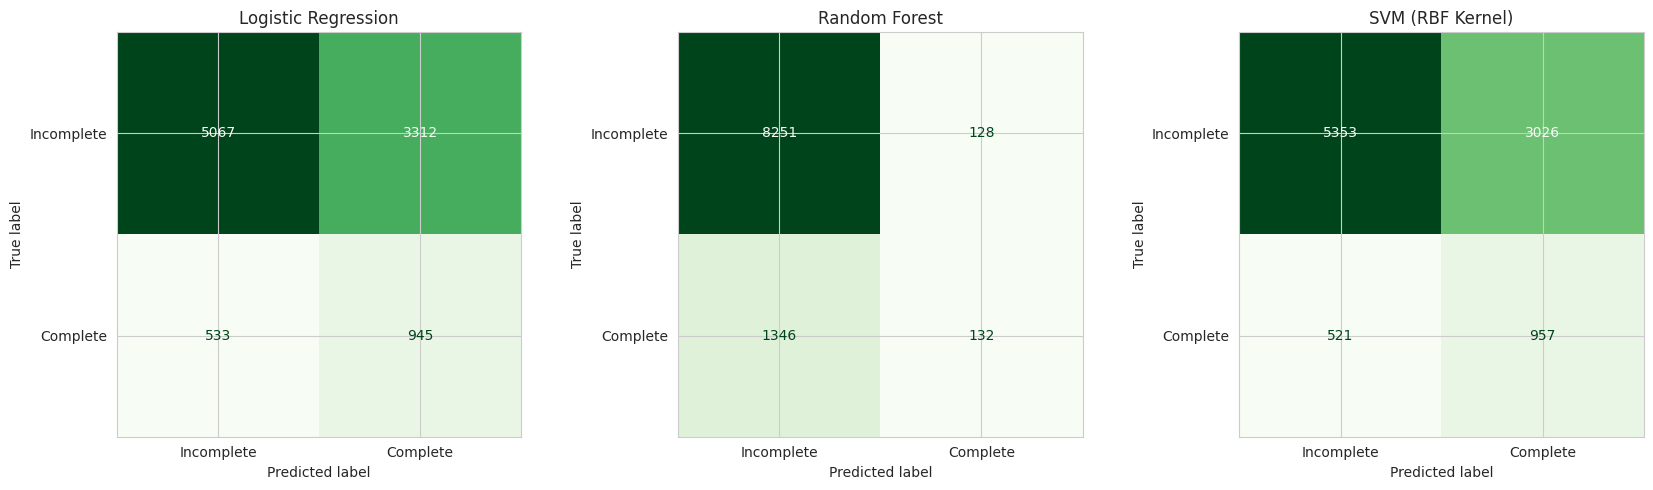

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Incomplete", "Complete"])
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [62]:
eval_results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    eval_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

eval_df = pd.DataFrame(eval_results).set_index("Model").round(4)
eval_df


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.6099,0.2220,0.6394,0.3296,0.6575
Random Forest,0.8505,0.5077,0.0893,0.1519,0.7622
SVM (RBF Kernel),0.6402,0.2403,0.6475,0.3505,0.6924


=== 5-fold CV (train set) ===
             mean     std
accuracy   0.8501  0.0009
precision  0.5022  0.0179
recall     0.0786  0.0081
f1         0.1358  0.0123
roc_auc    0.7667  0.0020
booking_origin           0.1390
route                    0.0448
flight_duration          0.0365
length_of_stay           0.0298
wants_extra_baggage      0.0127
purchase_lead            0.0117
wants_preferred_seat     0.0074
sales_channel            0.0073
wants_in_flight_meals    0.0051
flight_hour              0.0021
trip_type                0.0006
flight_day              -0.0005
num_passengers          -0.0016
dtype: float64


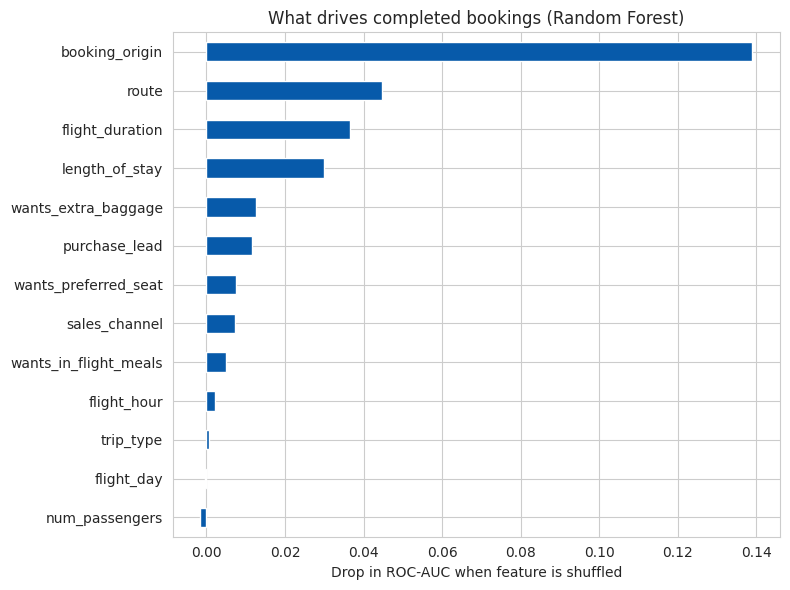

In [63]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# ---- 5-fold stratified cross-validation (Random Forest, default threshold 0.5) ----
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
cv_res = cross_validate(rf, X_train_scaled, y_train, cv=cv, scoring=scoring, n_jobs=-1)
cv_df = pd.DataFrame({m: [cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std()] for m in scoring},
                     index=["mean", "std"]).T.round(4)
print("=== 5-fold CV (train set) ===")
print(cv_df)

# ---- Feature importance (permutation, on the held-out test set) ----
rf.fit(X_train_scaled, y_train)
perm = permutation_importance(rf, X_test_scaled, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()
print(imp.sort_values(ascending=False).round(4))

plt.figure(figsize=(8, 6))
imp.plot(kind="barh", color="#075AAA")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.title("What drives completed bookings (Random Forest)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=200)
plt.show()